# Lab | Summarization evaluation using LangSmith
Let's revisit your capstone project 2? Well, sort of. Pick diffierent sets of data and re-run this notebook. Maybe parts of the dataset you used in your last project week. The point is for you to understand all steps involve and the many different ways one can and should evaluate LLM applications using LangSmith.

What did you learn? - Let's discuss that in class

## LangSmith - LangChain evaluation

> ⚠️ **Updated:** Original notebook loaded API keys from a `.env` file using `dotenv`. This updated version uses `getpass` so you can enter keys directly at runtime without needing a `.env` file.

In [1]:
import os
from getpass import getpass

OPENAI_API_KEY = getpass('Please enter your OpenAI API Key: ')
LANGCHAIN_API_KEY = getpass('Please enter your LangChain API Key: ')
HUGGINGFACEHUB_API_TOKEN = getpass('Please enter your HuggingFace Hub API Token: ')

os.environ['OPENAI_API_KEY'] = OPENAI_API_KEY
os.environ['LANGCHAIN_API_KEY'] = LANGCHAIN_API_KEY
os.environ['HUGGINGFACEHUB_API_TOKEN'] = HUGGINGFACEHUB_API_TOKEN

Please enter your OpenAI API Key: ··········
Please enter your LangChain API Key: ··········
Please enter your HuggingFace Hub API Token: ··········


In [2]:
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGCHAIN_ENDPOINT"]="https://api.smith.langchain.com"
os.environ["LANGCHAIN_PROJECT"]="langsmith_max-test"

In [3]:
#Importing Client from Langsmith
from langsmith import Client
client = Client(api_key=LANGCHAIN_API_KEY)

### Create Dataset


> ⚠️ **Updated:** Original used `ccdv/cnn_dailymail` with `version=` and `trust_remote_code=True` which are no longer supported. Updated to use `cnn_dailymail` with `name=` parameter.

In [4]:
from datasets import load_dataset
cnn_dataset = load_dataset("cnn_dailymail", name="3.0.0")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

3.0.0/train-00000-of-00003.parquet:   0%|          | 0.00/257M [00:00<?, ?B/s]

3.0.0/train-00001-of-00003.parquet:   0%|          | 0.00/257M [00:00<?, ?B/s]

3.0.0/train-00002-of-00003.parquet:   0%|          | 0.00/259M [00:00<?, ?B/s]

3.0.0/validation-00000-of-00001.parquet:   0%|          | 0.00/34.7M [00:00<?, ?B/s]

3.0.0/test-00000-of-00001.parquet:   0%|          | 0.00/30.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/287113 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/13368 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

In [5]:
def add_prefix(example):
    return {
        **example,
        "article": f"Summarize this news:\n{example['article']}"
    }

#cnn_dataset = cnn_dataset.map(add_prefix)

In [6]:
cnn_dataset

DatasetDict({
    train: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 287113
    })
    validation: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 13368
    })
    test: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 11490
    })
})

In [7]:
cnn_dataset['train'][0]

{'article': 'LONDON, England (Reuters) -- Harry Potter star Daniel Radcliffe gains access to a reported £20 million ($41.1 million) fortune as he turns 18 on Monday, but he insists the money won\'t cast a spell on him. Daniel Radcliffe as Harry Potter in "Harry Potter and the Order of the Phoenix" To the disappointment of gossip columnists around the world, the young actor says he has no plans to fritter his cash away on fast cars, drink and celebrity parties. "I don\'t plan to be one of those people who, as soon as they turn 18, suddenly buy themselves a massive sports car collection or something similar," he told an Australian interviewer earlier this month. "I don\'t think I\'ll be particularly extravagant. "The things I like buying are things that cost about 10 pounds -- books and CDs and DVDs." At 18, Radcliffe will be able to gamble in a casino, buy a drink in a pub or see the horror film "Hostel: Part II," currently six places below his number one movie on the UK box office char

In [8]:
#Get just a few news to test
MAX_NEWS=10
sample_cnn = cnn_dataset["test"].select(range(MAX_NEWS)).map(add_prefix)

sample_cnn

Map:   0%|          | 0/10 [00:00<?, ? examples/s]

Dataset({
    features: ['article', 'highlights', 'id'],
    num_rows: 10
})

The dataset contains three columns: article, highlights, and id. To use LangSmith, we need to create a dataset in LangSmith format.

LangSmith expects a prompt and a result. To achieve this, we will transform the article into a prompt by adding the prefix: "Summarize this news." As a result, we will use the content of highlights, which represents the summaries created by humans.

In [9]:
print(sample_cnn[0])

{'article': 'Summarize this news:\n(CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC\'s founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed "in the occupied Palestinian territory, including East Jerusalem, since June 13, 2014." Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations against Israelis. As members of the court, Palestinians may be subject to counter-charges as well. Israel and the United States, neither of which is an ICC member, opposed the Palestinians\' efforts to join the body. But Palestinian Foreign Minister Riad al-Malki,

Now We have the Dataset with the prompt and the Reference Summary, it is time to create a Dataset in LangSmith with this information.
### Create the Dataset in Langsmith

The dataset in LangSmith is composed of an input, which is the prompt passed to the model for evaluation, and an output, which should contain what we expect the model to return.

In [10]:
import datetime

In [11]:
import uuid
input_key=['article']
output_key=['highlights']

NAME_DATASET=f"Summarize_dataset_{datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')}"

In [12]:
#This creates the dataset in LangSmith with the content in sample_cnn - If you run this more than once you will get POST errors
dataset = client.upload_dataframe(
    df=sample_cnn,
    input_keys=input_key,
    output_keys=output_key,
    name=NAME_DATASET,
    description="Test Embedding distance between model summarizations",
    data_type="kv"
)
print(f"✅ Dataset created: {NAME_DATASET}")

Creating CSV from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

✅ Dataset created: Summarize_dataset_2026-03-04 15:28:54


In this image, we can see an example from the dataset once it's been registered in LangSmith.

In the Input column, there is the prompt to be sent, while in the Output column, the expected output is stored.

When performing the comparison, the model will be given the prompt, and the Cosine distance between its response and the one stored in the sample dataset will be calculated.
<img src="https://github.com/peremartra/Large-Language-Model-Notebooks-Course/blob/main/img/Martra_Figure_4_2SDL_Dataset.jpg?raw=true">

### Recovering Models From Hugging Face
Let's retrieve both models from HuggingFace. A base model and a model that has been fine-tuned using the training portion of this same dataset to generate summaries.

> ⚠️ **Updated:** Original used `HuggingFaceHub` from `langchain` which is deprecated, and `t5-base` / `flax-community/t5-base-cnn-dm` which are no longer accessible via the HuggingFace Inference API. Updated to use direct HTTP requests to the HuggingFace Router API with `facebook/bart-large-cnn` as the base model (a reliable summarization model) and kept `flax-community/t5-base-cnn-dm` as the fine-tuned model.

In [13]:
import requests
import numpy as np
from openai import OpenAI

openai_client = OpenAI(api_key=OPENAI_API_KEY)

def hf_summarize(text, repo_id):
    API_URL = f'https://router.huggingface.co/hf-inference/models/{repo_id}'
    headers = {'Authorization': f'Bearer {HUGGINGFACEHUB_API_TOKEN}'}
    try:
        response = requests.post(API_URL, headers=headers, json={'inputs': text[:1024]})
        if response.status_code == 200:
            result = response.json()
            if isinstance(result, list):
                return result[0].get('summary_text') or result[0].get('generated_text', '')
            return str(result)
        return f'API Error: {response.status_code}'
    except Exception as e:
        return f'Error: {str(e)}'

# Base model: facebook/bart-large-cnn (replaces t5-base)
def summarizer_base(inputs):
    return hf_summarize(inputs, 'facebook/bart-large-cnn')

# Fine-tuned model: flax-community/t5-base-cnn-dm
def summarizer_finetuned(inputs):
    return hf_summarize(inputs, 'flax-community/t5-base-cnn-dm')

## Defining Evaluator
The first step is to define an evaluator, where we specify the variables we want to evaluate. In our case, I have chosen to measure only the "embedding_distance."

I've left the "string_distance" as a comment in case you want to conduct a test with two evaluations instead of one.

> ⚠️ **Updated:** Original used `run_on_dataset` and `RunEvalConfig` from `langchain.smith` which have been removed in newer LangChain versions. Updated to use `langsmith.evaluate` with a custom `embedding_distance_evaluator` function that computes cosine distance using OpenAI embeddings.

In [14]:
from langsmith import evaluate

def get_embedding(text):
    if not text or not str(text).strip():
        return np.zeros(1536)
    response = openai_client.embeddings.create(
        input=str(text)[:8000],
        model='text-embedding-3-small'
    )
    return np.array(response.data[0].embedding)

def embedding_distance_evaluator(run, example):
    prediction = (run.outputs or {}).get('output', '')
    reference = (example.outputs or {}).get('highlights', '')
    emb1 = get_embedding(str(prediction))
    emb2 = get_embedding(str(reference))
    cosine_sim = np.dot(emb1, emb2) / (np.linalg.norm(emb1) * np.linalg.norm(emb2) + 1e-9)
    return {'key': 'embedding_distance', 'score': 1 - cosine_sim}

#We are using just one of the multiple evaluators available on LangSmith.
#string_distance is left as a comment in case you want to add a second evaluator.
#string_distance_evaluator can be added to the evaluators list similarly.

### Running Evaluator
With the same configuration, we can launch two evaluations on the same dataset. One for each of the chosen models.

> ⚠️ **Updated:** Original used `run_on_dataset` with `summarizer_base` (t5-base). Updated to use `langsmith.evaluate` with `facebook/bart-large-cnn` as the base model since t5-base is no longer accessible via the HuggingFace Inference API.

In [15]:
def summarize_bart(inputs: dict):
    output = hf_summarize(inputs['article'], 'facebook/bart-large-cnn')
    return {'output': output}

bart_results = evaluate(
    summarize_bart,
    data=NAME_DATASET,
    evaluators=[embedding_distance_evaluator],
    experiment_prefix='BART-large-CNN',
    client=client,
)

View the evaluation results for experiment: 'BART-large-CNN-384772d9' at:
https://smith.langchain.com/o/d07e4bf3-240c-474f-a307-d7b91487d474/datasets/2747b5a9-829c-45aa-87c5-f28ff9168c30/compare?selectedSessions=336633e6-b519-4954-a228-ef93be11cbd9




0it [00:00, ?it/s]

> ⚠️ **Updated:** Original used `run_on_dataset` with `summarizer_finetuned`. Updated to use `langsmith.evaluate` with a direct HuggingFace API call.

In [16]:
def summarize_t5_finetuned(inputs: dict):
    output = hf_summarize(inputs['article'], 'flax-community/t5-base-cnn-dm')
    return {'output': output}

finetuned_t5_results = evaluate(
    summarize_t5_finetuned,
    data=NAME_DATASET,
    evaluators=[embedding_distance_evaluator],
    experiment_prefix='T5-FineTuned',
    client=client,
)

View the evaluation results for experiment: 'T5-FineTuned-9b01124f' at:
https://smith.langchain.com/o/d07e4bf3-240c-474f-a307-d7b91487d474/datasets/2747b5a9-829c-45aa-87c5-f28ff9168c30/compare?selectedSessions=9fa14a45-afaf-4ffe-8aa0-9f9a6a327d04




0it [00:00, ?it/s]

<img src="https://github.com/peremartra/Large-Language-Model-Notebooks-Course/blob/main/img/Martra_Figure_4_2SDL_Tests.jpg?raw=true">

In the image below you can see the comparision between two tests.
<img src="https://github.com/peremartra/Large-Language-Model-Notebooks-Course/blob/main/img/Martra_Figure_4_2SDL_CompareTestst.jpg?raw=true">

Well, since it has been so straightforward, why don't we try to make the comparison with an OpenAI model?

> ⚠️ **Updated:** Original used `from langchain.chat_models import ChatOpenAI` which is deprecated, and `run_on_dataset` which has been removed. Updated to use `from langchain_openai import ChatOpenAI` and `langsmith.evaluate`.

In [17]:
import sys
!{sys.executable} -m pip install langchain-openai

from langchain_openai import ChatOpenAI

open_aillm = ChatOpenAI(model='gpt-3.5-turbo', temperature=0.0, openai_api_key=OPENAI_API_KEY)

def summarize_openai(inputs: dict):
    article = inputs['article'][:3000]
    result = open_aillm.invoke(article)
    return {'output': result.content if result.content else 'No summary generated'}

openai_results = evaluate(
    summarize_openai,
    data=NAME_DATASET,
    evaluators=[embedding_distance_evaluator],
    experiment_prefix='OpenAI-GPT35',
    client=client,
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.2/87.2 kB 6.7 MB/s eta 0:00:00
View the evaluation results for experiment: 'OpenAI-GPT35-1501a757' at:
https://smith.langchain.com/o/d07e4bf3-240c-474f-a307-d7b91487d474/datasets/2747b5a9-829c-45aa-87c5-f28ff9168c30/compare?selectedSessions=26599cd5-73f7-402f-92ec-6a35cccc7981




0it [00:00, ?it/s]

<img src="https://github.com/peremartra/Large-Language-Model-Notebooks-Course/blob/main/img/Martra_Figure_4_2SDL_CompareOpenAI_HF.jpg?raw=true">

The experiment with the OpenAI model has yielded the best results. But, be aware! As we can see, there is a cost involved since we are using an API, and it needs to be paid for.

Another crucial piece of information is that we can view performance data for the models. This data could also be useful for minimally evaluating our inference server.

# Exercise Run - Benjamin Hunt

Following this lab I will:
1) load the CSV
2) map it to the same schema as the lab (article -> highlights)
3) upload it as a LangSmith Dataset
4) run the same evaluation on a few models
5) check results inside the LangSmith website



---



In [18]:
# Make result tables clearer and wider
from IPython.display import display, Markdown
import pandas as pd

# Make pandas display wider + show more text
pd.set_option("display.max_colwidth", 2000)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

### 1) Load our own CSV dataset (from Amazon user reviews project I did)

We load the file you uploaded and quickly check the columns.
We expect to see `ReviewBody` (long text) and `ReviewTitle` (short human summary).

In [19]:
import pandas as pd

# Load your dataset (uploaded into the notebook runtime)
reviews_path = "AllProductReviews.csv"
reviews_df = pd.read_csv(reviews_path)

reviews_df.head(8)

,ReviewTitle,ReviewBody,ReviewStar,Product
0,Honest review of an edm music lover\n,No doubt it has a great bass and to a great extent noise cancellation and decent sound clarity and mindblowing battery but the following dissapointed me though i tried a lot to adjust.1.Bluetooth range not more than 10m2. Pain in ear due the conical buds(can be removed)3. Wires are a bit long which makes it odd in front.4. No pouch provided.5. Worst part is very low quality and distoring mic. Other person keeps complaining about my voice.\n,3,boAt Rockerz 255
1,Unreliable earphones with high cost\n,"This earphones are unreliable, i bought it before 15 days meanwhile right side ear buds got cracked automatically and it got divided in two parts, and sound quality is also not that much good but ok, one more thing bass is not good as it is a boat earphones.Guys,Also for the proof i have attached picsPlease see and think before buying​ this unreliable product.Thanks.\n",1,boAt Rockerz 255
2,Really good and durable.\n,"i bought itfor 999,I purchased it second time, gifted first one to brother. This is really good.Sound quality is really good.You can connect 2 devices at a time.I connect laptop and mobile both.when listening muaic on Lappy, if u get a call, it switches to mobile,this switch between device is not good but again in this price its awesome.Battery stand by is 36 hours for me, and i have used it continously for 8 hours in one go. So Battery life is pretty awesome.Comfortable on ear.\n",4,boAt Rockerz 255
3,stopped working in just 14 days\n,Its sound quality is adorable. overall it was good but just for 2 weeks after that it stopped working and since then it never powered on again. I am claiming for warrenty and it is still undergoing.\n,1,boAt Rockerz 255
4,Just Awesome Wireless Headphone under 1000...😉\n,Its Awesome... Good sound quality & 8-9 hrs battery life... Just waww look... 😉 I brought just 999 rupees...But Amazon's Packageing system is Very bad... Very poor packaging... Flipcart's packaging system is much better than Amazon...\n,5,boAt Rockerz 255
5,Charging port not working\n,"After 11 days, the charging port isn't working and now I can't even return it. Wat to do ?? I know there is one year warranty but it is only been 11 days. C'mon boat, please send me new one.\n",1,boAt Rockerz 255
6,Loved the color and sound !!\n,Sound-4.5/5Build quality-4.5/5Battery life -4/5Earphones quality is good with strong magnetic lock... Straps is good quality and the earphones wires are too good... Buttons quality is good.. sound is full of punchy bass and and balanced treble and has sorrund effect.. good fitting in ears.. hope connectivity is good.. bcz my last boat Bluetooth bassheads 225 had connection issues... This is worth its price... Hope the packaging was good ...there was no bubble wrapping..\n,4,boAt Rockerz 255
7,Great sound with worst mic.\n,After one month usage reviewing this .Pros-1- sound quality2- design3- weight4- batteryCons1- very bad mic for talking2- can't use while riding bike3 - Music is too loud\n,3,boAt Rockerz 255


### Bonus: Light text cleanup (regex)

We clean only the raw review text for readability:
- turn newlines/tabs into spaces
- remove extra spaces
- fix spacing around punctuation
- reduce repeated dots and punctuation

This does not change the lab code. It only prepares our own dataset.

In [20]:
import re

def clean_review_text(text: str) -> str:
    if text is None:
        return ""
    s = str(text)
    s = re.sub(r"[\r\n\t]+", " ", s)
    s = re.sub(r"\s{2,}", " ", s)
    s = re.sub(r"\s+([.,!?;:])", r"\1", s)
    s = re.sub(r"([.,!?;:])([A-Za-z0-9])", r"\1 \2", s)
    s = re.sub(r"\.{4,}", "...", s)
    s = re.sub(r"([!?]){3,}", r"\1\1", s)
    return s.strip()

# Make sure these base columns exist in your CSV
reviews_df["ReviewBody_clean"] = reviews_df["ReviewBody"].apply(clean_review_text)
reviews_df["ReviewTitle_clean"] = reviews_df["ReviewTitle"].apply(clean_review_text)

print("✅ Clean columns added:", "ReviewBody_clean" in reviews_df.columns, "ReviewTitle_clean" in reviews_df.columns)
reviews_df[["ReviewTitle_clean", "ReviewBody_clean"]].head(2)

✅ Clean columns added: True True


,ReviewTitle_clean,ReviewBody_clean
0,Honest review of an edm music lover,No doubt it has a great bass and to a great extent noise cancellation and decent sound clarity and mindblowing battery but the following dissapointed me though i tried a lot to adjust. 1. Bluetooth range not more than 10m2. Pain in ear due the conical buds(can be removed)3. Wires are a bit long which makes it odd in front. 4. No pouch provided. 5. Worst part is very low quality and distoring mic. Other person keeps complaining about my voice.
1,Unreliable earphones with high cost,"This earphones are unreliable, i bought it before 15 days meanwhile right side ear buds got cracked automatically and it got divided in two parts, and sound quality is also not that much good but ok, one more thing bass is not good as it is a boat earphones. Guys, Also for the proof i have attached picsPlease see and think before buying​ this unreliable product. Thanks."


### Apply cleanup to our review body (and title)

We create cleaned versions of the text and then build `article` and `highlights`
from the cleaned fields.

In [21]:
work_df = reviews_df[["ReviewTitle", "ReviewBody"]].copy()

# Clean both fields (title is usually already short, but we normalize anyway)
work_df["ReviewTitle_clean"] = work_df["ReviewTitle"].apply(clean_review_text)
work_df["ReviewBody_clean"] = work_df["ReviewBody"].apply(clean_review_text)

# Drop empty rows after cleaning
work_df = work_df[(work_df["ReviewTitle_clean"] != "") & (work_df["ReviewBody_clean"] != "")]

# Build lab-compatible columns (same names as the lab)
work_df["article"] = "Summarize this product review:\n" + work_df["ReviewBody_clean"]
work_df["highlights"] = work_df["ReviewTitle_clean"]

MAX_REVIEWS = 30
sample_reviews = work_df[["article", "highlights"]].head(MAX_REVIEWS).reset_index(drop=True)

sample_reviews.head(10)

,article,highlights
0,Summarize this product review:\nNo doubt it has a great bass and to a great extent noise cancellation and decent sound clarity and mindblowing battery but the following dissapointed me though i tried a lot to adjust. 1. Bluetooth range not more than 10m2. Pain in ear due the conical buds(can be removed)3. Wires are a bit long which makes it odd in front. 4. No pouch provided. 5. Worst part is very low quality and distoring mic. Other person keeps complaining about my voice.,Honest review of an edm music lover
1,"Summarize this product review:\nThis earphones are unreliable, i bought it before 15 days meanwhile right side ear buds got cracked automatically and it got divided in two parts, and sound quality is also not that much good but ok, one more thing bass is not good as it is a boat earphones. Guys, Also for the proof i have attached picsPlease see and think before buying​ this unreliable product. Thanks.",Unreliable earphones with high cost
2,"Summarize this product review:\ni bought itfor 999, I purchased it second time, gifted first one to brother. This is really good. Sound quality is really good. You can connect 2 devices at a time. I connect laptop and mobile both. when listening muaic on Lappy, if u get a call, it switches to mobile, this switch between device is not good but again in this price its awesome. Battery stand by is 36 hours for me, and i have used it continously for 8 hours in one go. So Battery life is pretty awesome. Comfortable on ear.",Really good and durable.
3,Summarize this product review:\nIts sound quality is adorable. overall it was good but just for 2 weeks after that it stopped working and since then it never powered on again. I am claiming for warrenty and it is still undergoing.,stopped working in just 14 days
4,Summarize this product review:\nIts Awesome... Good sound quality & 8-9 hrs battery life... Just waww look... 😉 I brought just 999 rupees... But Amazon's Packageing system is Very bad... Very poor packaging... Flipcart's packaging system is much better than Amazon...,Just Awesome Wireless Headphone under 1000...😉
5,"Summarize this product review:\nAfter 11 days, the charging port isn't working and now I can't even return it. Wat to do?? I know there is one year warranty but it is only been 11 days. C'mon boat, please send me new one.",Charging port not working
6,Summarize this product review:\nSound-4. 5/5Build quality-4. 5/5Battery life -4/5Earphones quality is good with strong magnetic lock... Straps is good quality and the earphones wires are too good... Buttons quality is good.. sound is full of punchy bass and and balanced treble and has sorrund effect.. good fitting in ears.. hope connectivity is good.. bcz my last boat Bluetooth bassheads 225 had connection issues... This is worth its price... Hope the packaging was good... there was no bubble wrapping..,Loved the color and sound!!
7,Summarize this product review:\nAfter one month usage reviewing this. Pros-1- sound quality2- design3- weight4- batteryCons1- very bad mic for talking2- can't use while riding bike3 - Music is too loud,Great sound with worst mic.
8,Summarize this product review:\nI can’t get enough of this earphone! The bass is amazing and is perfect for a music lover. The battery life is good enough to keep me going all day. The fact that I can connect my laptop and phone at the same time and switch between them makes the experience so much better. I use my earphones a lot for voice calls and this doesn’t let me down at all. This is a must buy for all music lovers.,Battery life is good enough to keep going all day
9,Summarize this product review:\nThe product durability is 1 month.. I just lost my bill details so i cant claim my warrenty.. But this earphones built quality is bad. It stops wrking completely after 1 month sep 14 to nov 11 👈 life span.. Dont lose ur bill details incase u want that warranty.. And after purchasing u must register ur product in boat's site for replacement and wa

### Quick before/after check (first 3 rows)

This helps confirm the cleanup did what we wanted.

In [22]:
preview = work_df[["ReviewBody", "ReviewBody_clean", "ReviewTitle", "ReviewTitle_clean"]].head(3).copy()
preview

,ReviewBody,ReviewBody_clean,ReviewTitle,ReviewTitle_clean
0,No doubt it has a great bass and to a great extent noise cancellation and decent sound clarity and mindblowing battery but the following dissapointed me though i tried a lot to adjust.1.Bluetooth range not more than 10m2. Pain in ear due the conical buds(can be removed)3. Wires are a bit long which makes it odd in front.4. No pouch provided.5. Worst part is very low quality and distoring mic. Other person keeps complaining about my voice.\n,No doubt it has a great bass and to a great extent noise cancellation and decent sound clarity and mindblowing battery but the following dissapointed me though i tried a lot to adjust. 1. Bluetooth range not more than 10m2. Pain in ear due the conical buds(can be removed)3. Wires are a bit long which makes it odd in front. 4. No pouch provided. 5. Worst part is very low quality and distoring mic. Other person keeps complaining about my voice.,Honest review of an edm music lover\n,Honest review of an edm music lover
1,"This earphones are unreliable, i bought it before 15 days meanwhile right side ear buds got cracked automatically and it got divided in two parts, and sound quality is also not that much good but ok, one more thing bass is not good as it is a boat earphones.Guys,Also for the proof i have attached picsPlease see and think before buying​ this unreliable product.Thanks.\n","This earphones are unreliable, i bought it before 15 days meanwhile right side ear buds got cracked automatically and it got divided in two parts, and sound quality is also not that much good but ok, one more thing bass is not good as it is a boat earphones. Guys, Also for the proof i have attached picsPlease see and think before buying​ this unreliable product. Thanks.",Unreliable earphones with high cost\n,Unreliable earphones with high cost
2,"i bought itfor 999,I purchased it second time, gifted first one to brother. This is really good.Sound quality is really good.You can connect 2 devices at a time.I connect laptop and mobile both.when listening muaic on Lappy, if u get a call, it switches to mobile,this switch between device is not good but again in this price its awesome.Battery stand by is 36 hours for me, and i have used it continously for 8 hours in one go. So Battery life is pretty awesome.Comfortable on ear.\n","i bought itfor 999, I purchased it second time, gifted first one to brother. This is really good. Sound quality is really good. You can connect 2 devices at a time. I connect laptop and mobile both. when listening muaic on Lappy, if u get a call, it switches to mobile, this switch between device is not good but again in this price its awesome. Battery stand by is 36 hours for me, and i have used it continously for 8 hours in one go. So Battery life is pretty awesome. Comfortable on ear.",Really good and durable.\n,Really good and durable.


### 2) Convert our data into the same format as the lab

The lab expects:
- input: `article`
- reference output: `highlights`

We use:
- `ReviewBody_clean` for the input text (article)
- `ReviewTitle_clean` for the reference summary (highlights)

We also keep the sample small to run fast.

In [23]:
work_df = reviews_df[["ReviewTitle_clean", "ReviewBody_clean"]].copy()

# Clean up basic missing / empty values (final safety check)
work_df["ReviewTitle_clean"] = work_df["ReviewTitle_clean"].astype(str).str.strip()
work_df["ReviewBody_clean"] = work_df["ReviewBody_clean"].astype(str).str.strip()
work_df = work_df[(work_df["ReviewTitle_clean"] != "") & (work_df["ReviewBody_clean"] != "")]

# Match the lab column names
work_df["article"] = "Summarize this product review:\n" + work_df["ReviewBody_clean"]
work_df["highlights"] = work_df["ReviewTitle_clean"]

MAX_REVIEWS = 50
sample_reviews = work_df[["article", "highlights"]].head(MAX_REVIEWS).reset_index(drop=True)

sample_reviews.head(10)

,article,highlights
0,Summarize this product review:\nNo doubt it has a great bass and to a great extent noise cancellation and decent sound clarity and mindblowing battery but the following dissapointed me though i tried a lot to adjust. 1. Bluetooth range not more than 10m2. Pain in ear due the conical buds(can be removed)3. Wires are a bit long which makes it odd in front. 4. No pouch provided. 5. Worst part is very low quality and distoring mic. Other person keeps complaining about my voice.,Honest review of an edm music lover
1,"Summarize this product review:\nThis earphones are unreliable, i bought it before 15 days meanwhile right side ear buds got cracked automatically and it got divided in two parts, and sound quality is also not that much good but ok, one more thing bass is not good as it is a boat earphones. Guys, Also for the proof i have attached picsPlease see and think before buying​ this unreliable product. Thanks.",Unreliable earphones with high cost
2,"Summarize this product review:\ni bought itfor 999, I purchased it second time, gifted first one to brother. This is really good. Sound quality is really good. You can connect 2 devices at a time. I connect laptop and mobile both. when listening muaic on Lappy, if u get a call, it switches to mobile, this switch between device is not good but again in this price its awesome. Battery stand by is 36 hours for me, and i have used it continously for 8 hours in one go. So Battery life is pretty awesome. Comfortable on ear.",Really good and durable.
3,Summarize this product review:\nIts sound quality is adorable. overall it was good but just for 2 weeks after that it stopped working and since then it never powered on again. I am claiming for warrenty and it is still undergoing.,stopped working in just 14 days
4,Summarize this product review:\nIts Awesome... Good sound quality & 8-9 hrs battery life... Just waww look... 😉 I brought just 999 rupees... But Amazon's Packageing system is Very bad... Very poor packaging... Flipcart's packaging system is much better than Amazon...,Just Awesome Wireless Headphone under 1000...😉
5,"Summarize this product review:\nAfter 11 days, the charging port isn't working and now I can't even return it. Wat to do?? I know there is one year warranty but it is only been 11 days. C'mon boat, please send me new one.",Charging port not working
6,Summarize this product review:\nSound-4. 5/5Build quality-4. 5/5Battery life -4/5Earphones quality is good with strong magnetic lock... Straps is good quality and the earphones wires are too good... Buttons quality is good.. sound is full of punchy bass and and balanced treble and has sorrund effect.. good fitting in ears.. hope connectivity is good.. bcz my last boat Bluetooth bassheads 225 had connection issues... This is worth its price... Hope the packaging was good... there was no bubble wrapping..,Loved the color and sound!!
7,Summarize this product review:\nAfter one month usage reviewing this. Pros-1- sound quality2- design3- weight4- batteryCons1- very bad mic for talking2- can't use while riding bike3 - Music is too loud,Great sound with worst mic.
8,Summarize this product review:\nI can’t get enough of this earphone! The bass is amazing and is perfect for a music lover. The battery life is good enough to keep me going all day. The fact that I can connect my laptop and phone at the same time and switch between them makes the experience so much better. I use my earphones a lot for voice calls and this doesn’t let me down at all. This is a must buy for all music lovers.,Battery life is good enough to keep going all day
9,Summarize this product review:\nThe product durability is 1 month.. I just lost my bill details so i cant claim my warrenty.. But this earphones built quality is bad. It stops wrking completely after 1 month sep 14 to nov 11 👈 life span.. Dont lose ur bill details incase u want that warranty.. And after purchasing u must register ur product in boat's site for replacement and wa

### 3) Upload this dataset to LangSmith

We create a unique dataset name so reruns don’t clash.
This will appear in LangSmith under: Datasets.

In [24]:
import datetime
import uuid

timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
NAME_DATASET_REVIEWS = f"product_reviews_summarization_{timestamp}_{uuid.uuid4().hex[:6]}"

input_key = ["article"]
output_key = ["highlights"]

dataset_reviews = client.upload_dataframe(
    df=sample_reviews,
    input_keys=input_key,
    output_keys=output_key,
    name=NAME_DATASET_REVIEWS,
    description="Summarize ReviewBody and compare to ReviewTitle",
    data_type="kv",
)

print(f"✅ Dataset created in LangSmith: {NAME_DATASET_REVIEWS}")

✅ Dataset created in LangSmith: product_reviews_summarization_20260304_153101_7cccca


### 4) Run evaluation for Model #1 (BART)

We reuse the lab’s `hf_summarize()` helper and the same evaluator:
`embedding_distance_evaluator`.

This will create an Experiment in LangSmith under: Experiments.

In [25]:
def summarize_bart_reviews(inputs: dict) -> dict:
    output = hf_summarize(inputs["article"], "facebook/bart-large-cnn")
    return {"output": output}

bart_review_results = evaluate(
    summarize_bart_reviews,
    data=NAME_DATASET_REVIEWS,
    evaluators=[embedding_distance_evaluator],
    experiment_prefix="REVIEWS_BART-large-CNN",
    client=client,
)

View the evaluation results for experiment: 'REVIEWS_BART-large-CNN-2e878458' at:
https://smith.langchain.com/o/d07e4bf3-240c-474f-a307-d7b91487d474/datasets/33cefdd7-611c-4d0f-879a-c04534fe35a3/compare?selectedSessions=3da3897d-e4b8-4177-b1f6-caea4e7ac821




0it [00:00, ?it/s]

### 5) Run evaluation for Model #2 (fine-tuned T5)

Same idea, different HF model.
Create another experiment in LangSmith.

In [26]:
def summarize_t5_reviews(inputs: dict) -> dict:
    output = hf_summarize(inputs["article"], "flax-community/t5-base-cnn-dm")
    return {"output": output}

t5_review_results = evaluate(
    summarize_t5_reviews,
    data=NAME_DATASET_REVIEWS,
    evaluators=[embedding_distance_evaluator],
    experiment_prefix="REVIEWS_T5-FineTuned",
    client=client,
)

View the evaluation results for experiment: 'REVIEWS_T5-FineTuned-ad5ce7ec' at:
https://smith.langchain.com/o/d07e4bf3-240c-474f-a307-d7b91487d474/datasets/33cefdd7-611c-4d0f-879a-c04534fe35a3/compare?selectedSessions=882dc0fc-5583-4860-905c-8f5a7b43498f




0it [00:00, ?it/s]

### 6) Run evaluation for Model #3 (OpenAI from the lab)

We reuse the lab’s OpenAI setup (`open_aillm`).
This creates a third Experiment in LangSmith.

In [27]:
def summarize_openai_reviews(inputs: dict) -> dict:
    # Keep the input modest to avoid overly long prompts
    text = inputs["article"][:3000]
    result = open_aillm.invoke(text)
    return {"output": result.content if result.content else ""}

openai_review_results = evaluate(
    summarize_openai_reviews,
    data=NAME_DATASET_REVIEWS,
    evaluators=[embedding_distance_evaluator],
    experiment_prefix="REVIEWS_OpenAI",
    client=client,
)

View the evaluation results for experiment: 'REVIEWS_OpenAI-d4bf95d9' at:
https://smith.langchain.com/o/d07e4bf3-240c-474f-a307-d7b91487d474/datasets/33cefdd7-611c-4d0f-879a-c04534fe35a3/compare?selectedSessions=becb805b-468a-4a3c-9692-583c7f9acd76




0it [00:00, ?it/s]

## Check results in LangSmith (Website steps)

1) Datasets:
   - Go to "Datasets"
   - Search for the dataset name printed in the notebook
   - Open it and confirm you see `article` (input) and `highlights` (reference)

2) Experiments:
   - Go to "Experiments"
   - You should see:
     - REVIEWS_BART-large-CNN
     - REVIEWS_T5-FineTuned
     - REVIEWS_OpenAI
   - Open an experiment to see each row:
     input (article), reference (highlights), model output (output), and the score

3) How to read the score:
   - Lower `embedding_distance` generally means the summary is more similar to the reference title.
   - Use it mainly to compare models consistently.

## Summary so far

- We successfully created a LangSmith dataset (kv) and ran experiments.
- The `embedding_distance_evaluator` runs show a numeric score per example.
- However, our LangSmith UI shows 0 tokens / $0 cost.
- This strongly suggests we are mostly tracing evaluators (not LLM calls), or token usage is not being captured in the logged runs.
- Next: run two OpenAI-based experiments that should generate LLM call traces with token usage so we can compare cost.



---



## Cost Experiment (Run: 2): Run two OpenAI models on the same dataset

Goal: create two experiments where LangSmith logs LLM calls with token usage.
We will:
1) run a cheap model (example: gpt-4o-mini)
2) run a stronger model (example: gpt-4o)
Then we compare token usage and cost in LangSmith.

In [28]:
from langchain_openai import ChatOpenAI

# These are new model instances only for our experiment cells.
# (We are not changing the lab's OpenAI setup.)
llm_cheap = ChatOpenAI(model="gpt-4o-mini", temperature=0)
llm_strong = ChatOpenAI(model="gpt-4o", temperature=0)

### Run OpenAI model #1

This should create a normal LLM call trace (not only evaluator traces).

In [29]:
def summarize_openai_cheap(inputs: dict) -> dict:
    text = inputs["article"][:3000]
    result = llm_cheap.invoke(text)
    return {"output": result.content or ""}

openai_cheap_results = evaluate(
    summarize_openai_cheap,
    data=NAME_DATASET_REVIEWS,
    evaluators=[embedding_distance_evaluator],
    experiment_prefix="REVIEWS_OpenAI_gpt4o-mini",
    client=client,
)

View the evaluation results for experiment: 'REVIEWS_OpenAI_gpt4o-mini-d36af374' at:
https://smith.langchain.com/o/d07e4bf3-240c-474f-a307-d7b91487d474/datasets/33cefdd7-611c-4d0f-879a-c04534fe35a3/compare?selectedSessions=f80e550f-4e9d-4aa1-aa9a-7388d99cad1a




0it [00:00, ?it/s]

### Run OpenAI model #2 (stronger)

Same dataset and evaluator, different model.

In [30]:
def summarize_openai_strong(inputs: dict) -> dict:
    text = inputs["article"][:3000]
    result = llm_strong.invoke(text)
    return {"output": result.content or ""}

openai_strong_results = evaluate(
    summarize_openai_strong,
    data=NAME_DATASET_REVIEWS,
    evaluators=[embedding_distance_evaluator],
    experiment_prefix="REVIEWS_OpenAI_gpt4o",
    client=client,
)

View the evaluation results for experiment: 'REVIEWS_OpenAI_gpt4o-316fa361' at:
https://smith.langchain.com/o/d07e4bf3-240c-474f-a307-d7b91487d474/datasets/33cefdd7-611c-4d0f-879a-c04534fe35a3/compare?selectedSessions=ca7cebd3-86b6-418c-9973-27d46eb5ffbc




0it [00:00, ?it/s]

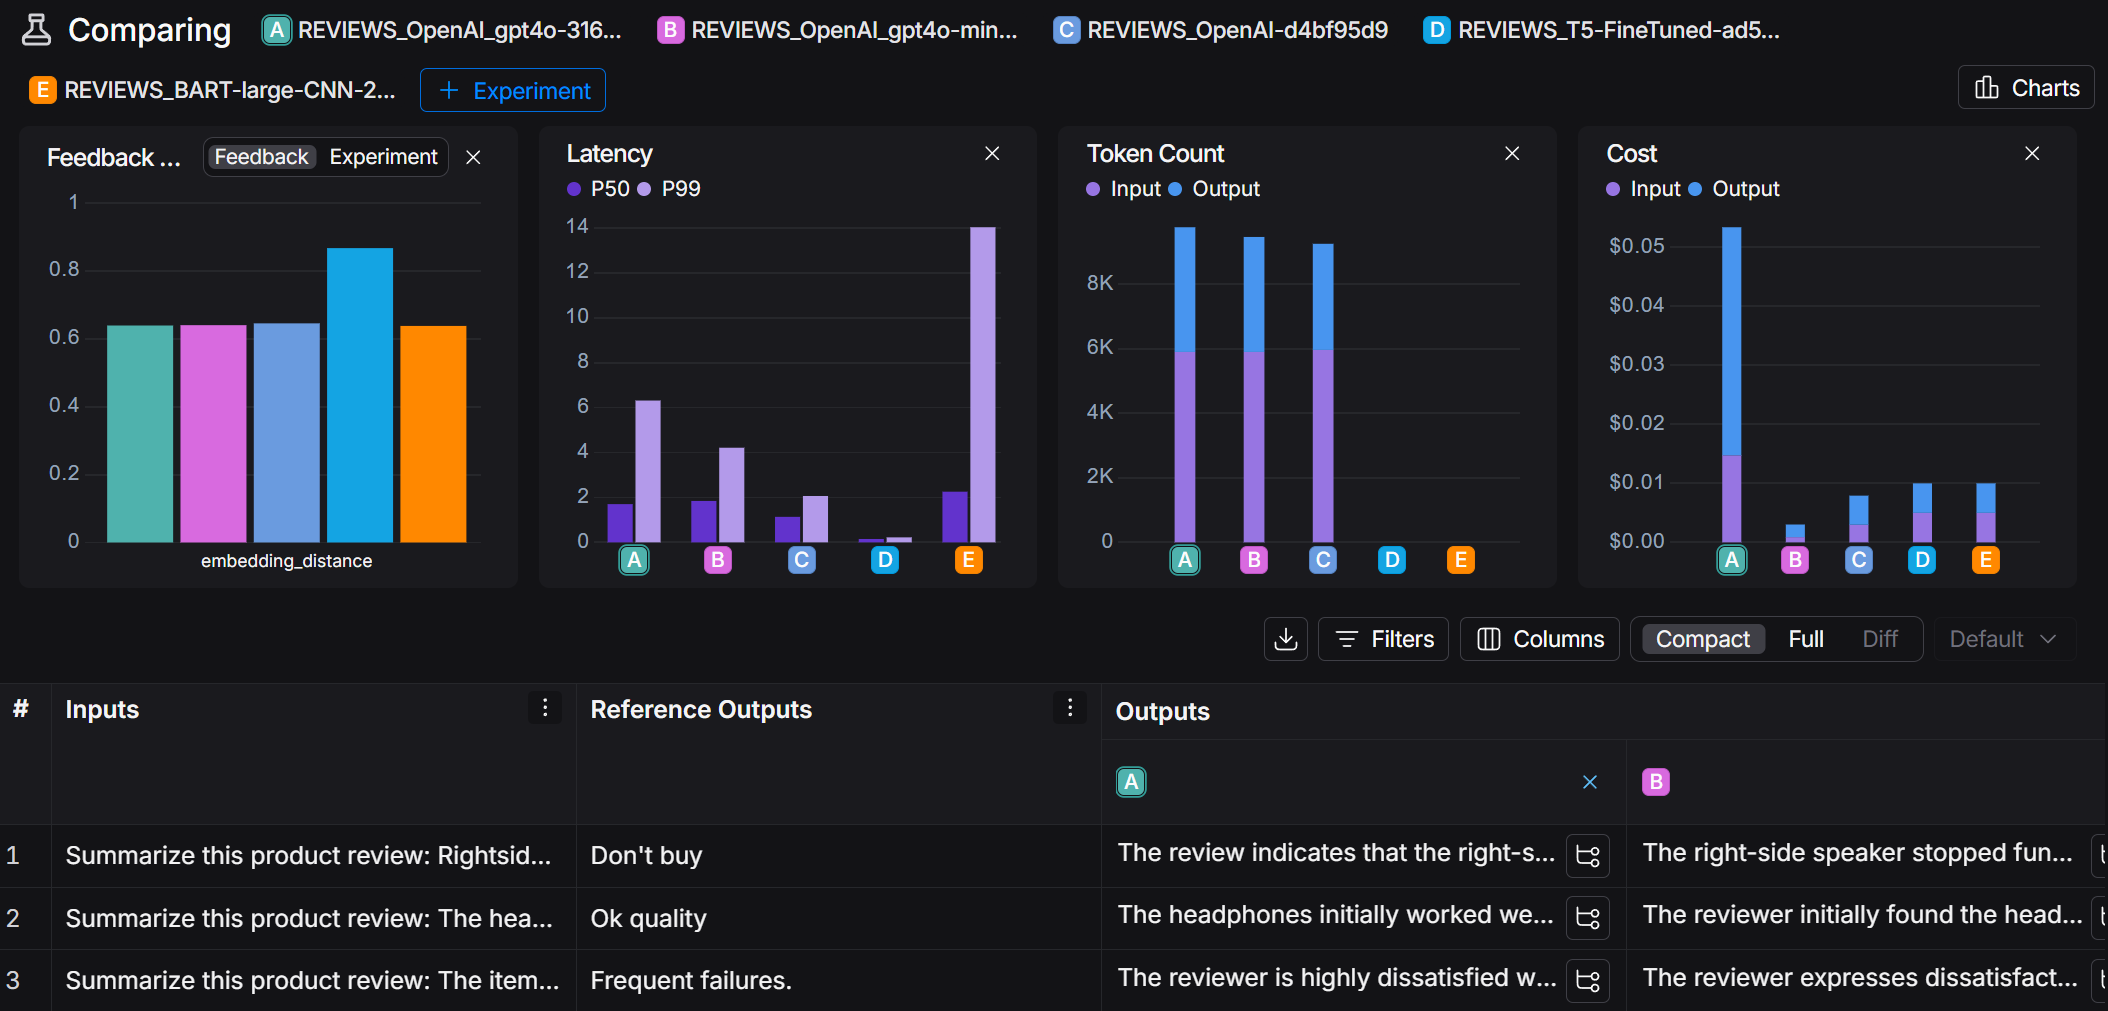

In [31]:
from IPython.display import Image, display

display(Image("/content/LangSmith compare.png"))

## Final Summary (LangSmith Summarization Evaluation Lab)

### What we built and tested
- We created a **LangSmith dataset** from product reviews with:
  - **Input**: `article` (review text + “Summarize this product review:” prefix)
  - **Reference output**: `highlights` (the review title used as a lightweight “ground truth”)
- We ran multiple **experiments** on the same dataset using different summarizers:
  - OpenAI models (multiple variants)
  - Hugging Face summarizers (e.g., BART / T5 variants)

### How we evaluated
- We used an **embedding distance evaluator** to compare:
  - the model’s generated summary (output)
  - vs the reference title (`highlights`)
- Interpretation:
  - **Lower embedding distance = closer semantic match to the title**
  - **Higher embedding distance = less semantic match**
- Important caveat:
  - Review titles are often **imperfect references** (too short, vague, or not aligned with the full review).
  - So embedding distance is useful as a **proxy**, not a full “truth” metric for summary quality.

### What LangSmith showed us (the key value)
- **Experiment comparison view** let us compare models side-by-side on:
  1) **Quality proxy** (embedding distance)
  2) **Latency** (P50/P99)
  3) **Token count** (input/output)
  4) **Cost** (input/output)
- We could quickly identify tradeoffs:
  - Some models are **cheaper/faster** but may score similarly or slightly worse.
  - Some models are **more expensive** (often due to output tokens + model pricing) and may not always justify the cost if the score improvement is small.
  - Local/HF models may show different token/cost behavior depending on how usage is tracked.

### Practical takeaways (if this were a real deployment)
- You should evaluate on **more than one metric**, because one number can hide failure modes.
- For a real production benchmark, we would ideally:
  - Create a small **gold set** (30–100 examples) with **human-written reference summaries**
  - Add additional checks:
    - length/format constraints
    - “coverage” (did it capture the key complaint/praise?)
    - hallucination risk (summary inventing details)
- Deployment readiness is a balance of:
  - **Quality**
  - **Cost**
  - **Latency**
  - **Reliability** (error rate)

### What we learned overall
- LangSmith is most valuable for:
  - **repeatable experiments**
  - **traceability** (every score links back to the exact input/output)
  - **fast iteration** through clear comparisons and dashboards
- We now have a working pattern to reuse in the final project:
  - dataset → experiments → evaluators → comparison → selection based on tradeoffs